# Models

Same hold-out for logistic regression, random forest, and XGBoost. The search scores macro F1. High vs low risk (classes 5-8 vs 1-4) is a second set of metrics, not a second model.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "prep.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

from models import load_split, run_models

arts = load_split()
X_train, X_test = arts["X_train"], arts["X_test"]
y_train, y_test = arts["y_train"], arts["y_test"]
print(f"Train {X_train.shape} | Hold-out {X_test.shape}")
print(y_train.value_counts(normalize=True).sort_index().map("{:.1%}".format))


Train (47504, 134) | Hold-out (11877, 134)
Response
1    10.5%
2    11.0%
3     1.7%
4     2.4%
5     9.1%
6    18.9%
7    13.5%
8    32.8%
Name: proportion, dtype: str


Set `QUICK = True` to skip the search. The default run is the one `run.py` uses.


In [2]:

QUICK = False
results = run_models(n_iter=8, cv_folds=3, quick=QUICK)
comparison = results["comparison"]
display(comparison.drop(columns=["best_params"], errors="ignore"))
print("Best model:", results["best_model"])



=== logistic_regression ===
Fitting 3 folds for each of 8 candidates, totalling 24 fits


  hold-out accuracy=0.432  macro_f1=0.338  OvR AUC=0.802  binary Gini=0.545

=== random_forest ===
Fitting 3 folds for each of 8 candidates, totalling 24 fits


  hold-out accuracy=0.516  macro_f1=0.413  OvR AUC=0.832  binary Gini=0.559

=== xgboost ===
Fitting 3 folds for each of 8 candidates, totalling 24 fits


  hold-out accuracy=0.528  macro_f1=0.430  OvR AUC=0.841  binary Gini=0.617

Best hold-out model (macro F1): xgboost
Saved models to artefacts/wp3


,model,accuracy,macro_precision,macro_recall,macro_f1,ovr_roc_auc_macro,ovr_gini_macro,binary_accuracy,binary_macro_f1,binary_roc_auc,binary_gini,cv_macro_f1_mean
0,logistic_regression,0.432180,0.348642,0.411109,0.338402,0.801860,0.603720,0.708175,0.660144,0.772547,0.545094,0.336123
1,random_forest,0.515787,0.423170,0.435123,0.412857,0.832033,0.664067,0.765513,0.669820,0.779308,0.558615,0.401019
2,xgboost,0.527827,0.431316,0.449686,0.430254,0.841478,0.682956,0.775364,0.701605,0.808345,0.616689,0.418741


Best model: xgboost


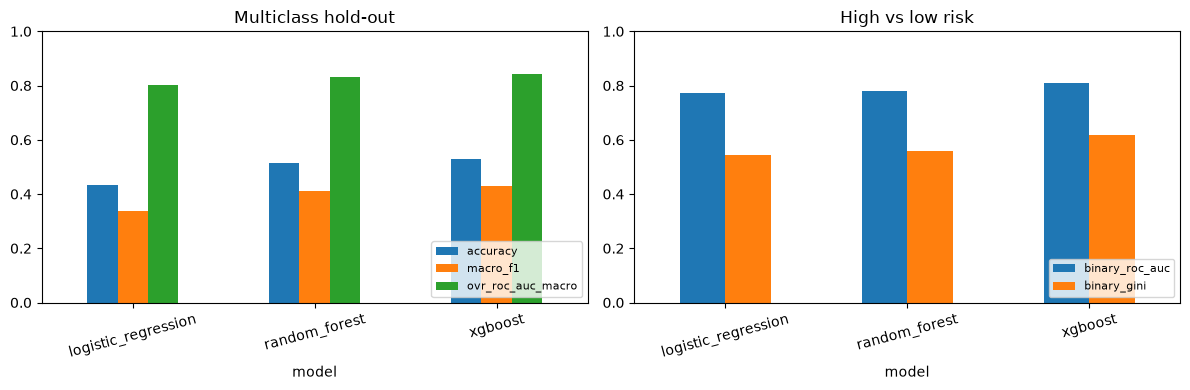

In [3]:

plot_df = comparison.set_index("model")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_df[["accuracy", "macro_f1", "ovr_roc_auc_macro"]].plot(kind="bar", ax=axes[0], rot=15)
axes[0].set_ylim(0, 1)
axes[0].set_title("Multiclass hold-out")
axes[0].legend(loc="lower right", fontsize=8)
plot_df[["binary_roc_auc", "binary_gini"]].plot(kind="bar", ax=axes[1], rot=15)
axes[1].set_ylim(0, 1)
axes[1].set_title("High vs low risk")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()


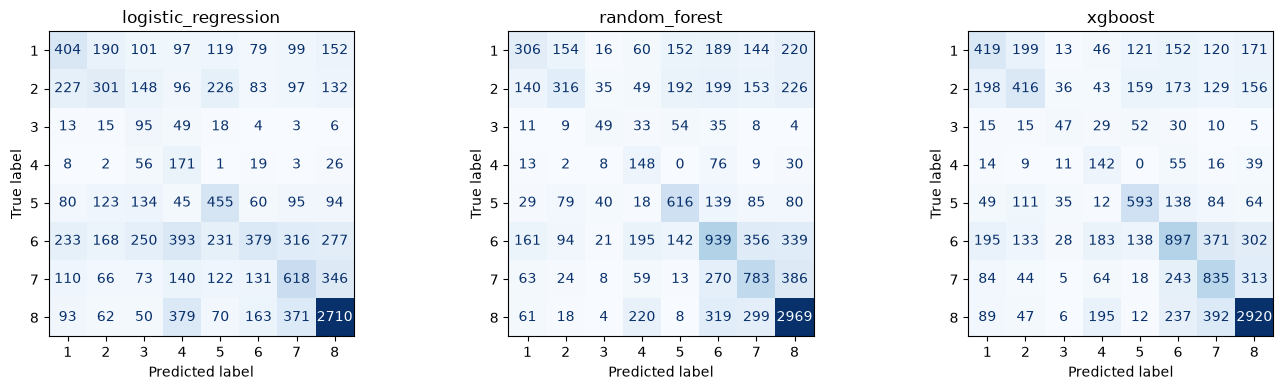

logistic_regression
              precision    recall  f1-score   support

           1      0.346     0.326     0.335      1241
           2      0.325     0.230     0.269      1310
           3      0.105     0.468     0.171       203
           4      0.125     0.598     0.207       286
           5      0.366     0.419     0.391      1086
           6      0.413     0.169     0.239      2247
           7      0.386     0.385     0.385      1606
           8      0.724     0.695     0.709      3898

    accuracy                          0.432     11877
   macro avg      0.349     0.411     0.338     11877
weighted avg      0.478     0.432     0.439     11877

Best params: {'clf__C': 7.196856730011514}
random_forest
              precision    recall  f1-score   support

           1      0.390     0.247     0.302      1241
           2      0.454     0.241     0.315      1310
           3      0.271     0.241     0.255       203
           4      0.189     0.517     0.277       286
 

In [4]:

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, ["logistic_regression", "random_forest", "xgboost"]):
    cm = np.array(results[name]["holdout"]["confusion_matrix"])
    ConfusionMatrixDisplay(cm, display_labels=list(range(1, 9))).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name in ["logistic_regression", "random_forest", "xgboost"]:
    print("=" * 60)
    print(name)
    print(results[name]["holdout"]["classification_report"])
    print("Best params:", results[name]["tune"]["best_params"])
